# Onde há pistas para prever o mês seguinte?

Uma primeira olhada nas cinco variáveis do projeto de mestrado *Modelagem de Padrões Espaço-Temporais para Previsão Subsazonal de Variáveis Meteorológicas* (INPE), no Sudeste da América do Sul.

Antes de treinar qualquer modelo, quis saber onde existe alguma pista para prever o mês seguinte. Olhei duas pistas simples.

1. **Memória.** Quando um mês fica acima do normal, o mês seguinte também tende a ficar?
2. **El Niño.** O Niño 3.4 de um mês diz algo sobre o mês seguinte aqui?

As duas perguntas são respondidas com correlações. Não há modelo de previsão neste notebook, só um mapa de onde vale a pena procurar.

## 1. Os dados

Uso as médias mensais do ERA5 de 1979 a 2025, a 1°, no mesmo recorte do IC do Cláudio Duarte (de 14°S a 40°S e de 67°W a 43°W). O Niño 3.4 é a temperatura da superfície do mar do ERSSTv5, publicada pelo NOAA.

O ERA5 não tem umidade específica perto da superfície pronta, então eu a calculo a partir do ponto de orvalho e da pressão em superfície (Bolton, 1980). Para a pressão uso a pressão ao nível do mar, e para o vento a velocidade a 10 m.

O download precisa de uma conta no [Copernicus CDS](https://cds.climate.copernicus.eu) e leva alguns minutos. Faço um pedido por variável porque o CDS recusa pedidos grandes. Arquivos que já existem não são baixados de novo.

In [1]:
import urllib.request
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm

DADOS = Path("../data/raw")
NINO34_URL = "https://www.cpc.ncep.noaa.gov/data/indices/ersst5.nino.mth.91-20.ascii"
ERA5 = {  # nome no arquivo e nome no CDS
    "t2m": "2m_temperature",
    "tp": "total_precipitation",
    "d2m": "2m_dewpoint_temperature",
    "sp": "surface_pressure",
    "msl": "mean_sea_level_pressure",
    "si10": "10m_wind_speed",
    "lsm": "land_sea_mask",
}


def baixa_era5(curto, nome):
    arquivo = DADOS / f"era5_mensal_{curto}.nc"
    if arquivo.exists():
        return
    fixo = curto == "lsm"  # a máscara terra e mar não muda, basta um mês
    pedido = {
        "product_type": ["monthly_averaged_reanalysis"],
        "variable": [nome],
        "year": ["2000"] if fixo else [str(ano) for ano in range(1979, 2026)],
        "month": ["01"] if fixo else [f"{mes:02d}" for mes in range(1, 13)],
        "time": ["00:00"],
        "area": [-14, -67, -40, -43],  # norte, oeste, sul, leste
        "grid": [1.0, 1.0],
        "data_format": "netcdf",
        "download_format": "unarchived",
    }
    cdsapi.Client().retrieve("reanalysis-era5-single-levels-monthly-means", pedido, str(arquivo))


DADOS.mkdir(parents=True, exist_ok=True)
for curto, nome in ERA5.items():
    baixa_era5(curto, nome)
if not (DADOS / "nino34_ersst5.txt").exists():
    urllib.request.urlretrieve(NINO34_URL, DADOS / "nino34_ersst5.txt")

In [2]:
def abre(curto):
    ds = xr.open_dataset(DADOS / f"era5_mensal_{curto}.nc")
    da = ds[curto].rename(valid_time="time", latitude="lat", longitude="lon")
    # a precipitação vem marcada às 6 h; deixo todas as datas no primeiro dia do mês
    da = da.assign_coords(time=da["time"].dt.floor("D"))
    return da.drop_vars(["number", "expver"], errors="ignore").sortby("lat").load()


t2m, tp, d2m, sp, msl, si10 = (abre(c) for c in ["t2m", "tp", "d2m", "sp", "msl", "si10"])
terra = abre("lsm").squeeze(drop=True) >= 0.5

# umidade específica a 2 m (g/kg) a partir do ponto de orvalho e da pressão (Bolton, 1980)
orvalho = d2m - 273.15
vapor = 6.112 * np.exp(17.67 * orvalho / (orvalho + 243.5))  # pressão de vapor em hPa
umidade = 622 * vapor / (sp / 100 - 0.378 * vapor)

VARIAVEIS = {
    "Temperatura a 2 m (°C)": t2m - 273.15,
    "Precipitação (mm/dia)": tp * 1000,
    "Umidade específica a 2 m (g/kg)": umidade,
    "Pressão ao nível do mar (hPa)": msl / 100,
    "Vento a 10 m (m/s)": si10,
}

tabela = pd.read_csv(DADOS / "nino34_ersst5.txt", sep=r"\s+")
meses = pd.to_datetime({"year": tabela["YR"], "month": tabela["MON"], "day": 1})
nino = xr.DataArray(tabela["NINO3.4"].values, dims="time", coords={"time": meses.values})
nino = nino.sel(time=slice("1979", "2025"))

pd.DataFrame({nome: [float(x.mean()), float(x.min()), float(x.max())]
              for nome, x in VARIAVEIS.items()}, index=["média", "mínimo", "máximo"]).round(1)

,Temperatura a 2 m (°C),Precipitação (mm/dia),Umidade específica a 2 m (g/kg),Pressão ao nível do mar (hPa),Vento a 10 m (m/s)
média,19.9,3.4,10.9,1014.3,4.0
mínimo,-13.2,0.0,0.3,1001.2,0.9
máximo,33.3,32.0,20.4,1026.8,12.0


## 2. De valores para anomalias

Prever que julho é mais frio que janeiro não tem mérito. Por isso trabalho com a anomalia, que é o quanto cada mês fugiu do normal daquele mês do ano. Em cada ponto faço três passos.

1. Tiro a média de cada mês do calendário, que é o ciclo anual.
2. Tiro a tendência linear de 1979 a 2025, para que o aquecimento não pareça memória.
3. Divido pelo desvio padrão de cada mês do calendário, para que os meses mais variáveis não pesem mais que os outros.

O Niño 3.4 passa pelos mesmos três passos.

In [3]:
def anomalia(x):
    a = x.groupby("time.month") - x.groupby("time.month").mean()
    tendencia = xr.polyval(a["time"], a.polyfit("time", deg=1).polyfit_coefficients)
    a = a - tendencia
    return (a.groupby("time.month") / a.groupby("time.month").std()).drop_vars("month")


anomalias = {nome: anomalia(x) for nome, x in VARIAVEIS.items()}
nino = anomalia(nino)

## 3. Memória e El Niño

A **memória** é a correlação entre a anomalia de um mês e a do mês seguinte, no mesmo ponto. A **pista do El Niño** é a correlação entre o Niño 3.4 de um mês e a anomalia do mês seguinte aqui. Nas duas o alvo é sempre o mês seguinte, como numa previsão de verdade.

Com 47 anos de dados, uma correlação pequena pode aparecer só por acaso. Por isso calculo em cada ponto o menor valor que dificilmente sairia por acaso, com 95% de confiança. Como meses seguidos se parecem, há menos informação independente do que o número de meses sugere. Levo isso em conta com o número efetivo de amostras de Bretherton et al. (1999). Nos mapas, os pontos abaixo desse limite ficam em branco.

In [4]:
def correlacao(a, b):
    """Correlação entre a em um mês e b no mês seguinte."""
    return xr.corr(a, b.shift(time=-1), dim="time")


def limite_95(n, r1, r2):
    """Menor correlação significativa a 95%, com n efetivo de Bretherton et al. (1999)."""
    n_efetivo = n * (1 - r1 * r2) / (1 + r1 * r2)
    return np.tanh(1.96 / np.sqrt(n_efetivo - 3))


n = nino.sizes["time"] - 1
memoria_nino = float(correlacao(nino, nino))
memoria, el_nino, sig_memoria, sig_nino = {}, {}, {}, {}
for nome, a in anomalias.items():
    memoria[nome] = correlacao(a, a)
    el_nino[nome] = correlacao(nino, a)
    sig_memoria[nome] = abs(memoria[nome]) >= limite_95(n, 0, 0)
    sig_nino[nome] = abs(el_nino[nome]) >= limite_95(n, memoria[nome].clip(min=0), memoria_nino)

print(f"memória do próprio Niño 3.4 de um mês para o outro {memoria_nino:.2f}")
print(f"limite para a memória {limite_95(n, 0, 0):.2f}")

memória do próprio Niño 3.4 de um mês para o outro 0.95
limite para a memória 0.08


## 4. Os mapas

Vermelho quer dizer que as duas coisas andam juntas. Azul quer dizer que andam em sentidos opostos. Na linha do El Niño, azul na precipitação significa que o El Niño vem seguido de menos chuva que o normal.

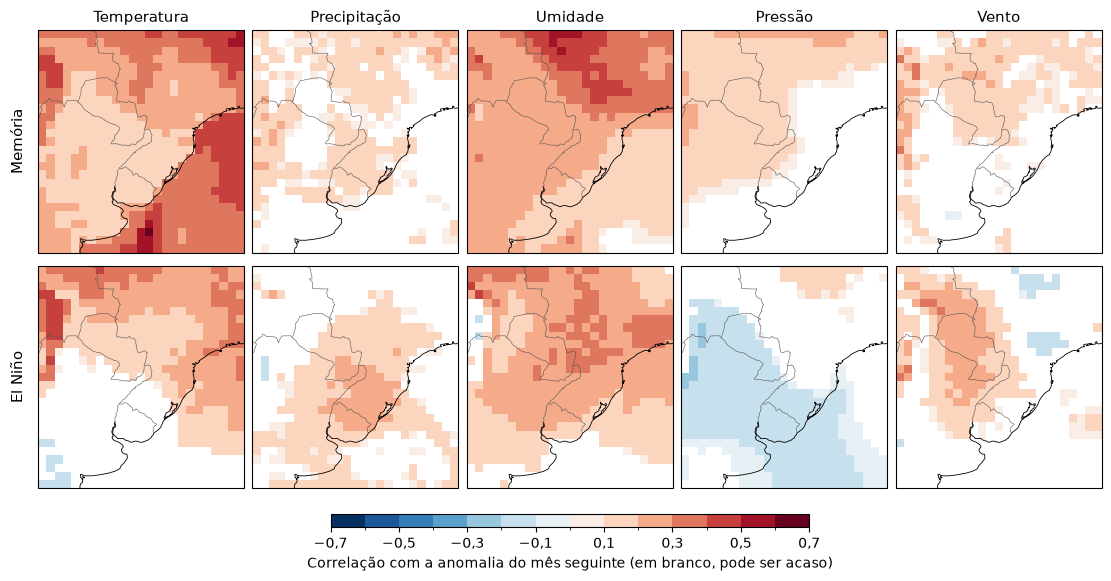

In [5]:
TITULOS = ["Temperatura", "Precipitação", "Umidade", "Pressão", "Vento"]
LINHAS = [("Memória", memoria, sig_memoria), ("El Niño", el_nino, sig_nino)]
niveis = np.round(np.arange(-0.7, 0.71, 0.1), 1)

fig, eixos = plt.subplots(2, 5, figsize=(11, 5.6), layout="constrained",
                          subplot_kw={"projection": ccrs.PlateCarree()})
for i, (rotulo, campos, significativo) in enumerate(LINHAS):
    for j, nome in enumerate(VARIAVEIS):
        ax = eixos[i, j]
        mapa = campos[nome].where(significativo[nome]).plot.pcolormesh(
            ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
            norm=BoundaryNorm(niveis, 256), add_colorbar=False)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.4, edgecolor="#555555")
        ax.set_extent([-67.5, -42.5, -40.5, -13.5], crs=ccrs.PlateCarree())
        ax.set_title(TITULOS[j] if i == 0 else "", fontsize=11)
        if j == 0:
            ax.text(-0.06, 0.5, rotulo, transform=ax.transAxes, rotation=90,
                    ha="right", va="center", fontsize=11)

barra = fig.colorbar(mapa, ax=eixos, orientation="horizontal", shrink=0.45, aspect=35,
                     ticks=niveis[::2])
barra.set_ticklabels([f"{v:.1f}".replace(".", ",").replace("-", "−") for v in niveis[::2]])
barra.set_label("Correlação com a anomalia do mês seguinte (em branco, pode ser acaso)")
Path("../results/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../results/figures/cinco_variaveis.png", dpi=220, bbox_inches="tight")

## 5. Os números por região

Médias da região ponderadas pela área de cada ponto (cosseno da latitude), separando continente e oceano. A última coluna diz que parte da região tem uma pista do El Niño que dificilmente é acaso.

In [6]:
peso = np.cos(np.deg2rad(terra["lat"])) * xr.ones_like(terra, dtype=float)


def media(campo, onde):
    return float(campo.where(onde).weighted(peso).mean(("lat", "lon")))


def area(significativo):
    return 100 * float(significativo.weighted(peso).mean(("lat", "lon")))


pd.DataFrame({
    "memória no continente": [media(memoria[v], terra) for v in VARIAVEIS],
    "memória no oceano": [media(memoria[v], ~terra) for v in VARIAVEIS],
    "maior pista do El Niño": [float(abs(el_nino[v]).max()) for v in VARIAVEIS],
    "área com pista do El Niño (%)": [area(sig_nino[v]) for v in VARIAVEIS],
}, index=TITULOS).round(2)

,memória no continente,memória no oceano,maior pista do El Niño,área com pista do El Niño (%)
Temperatura,0.24,0.38,0.48,64.33
Precipitação,0.10,0.03,0.28,48.57
Umidade,0.29,0.15,0.43,83.70
Pressão,0.12,0.04,0.24,56.47
Vento,0.10,0.01,0.34,39.81


## 6. O que eu vi

- **A temperatura é a variável com mais memória**, sobretudo no oceano (0,38 contra 0,24 no continente). A água guarda calor por mais tempo que a terra.
- **A umidade faz o contrário.** Ela lembra mais no continente (0,29) que no oceano (0,15), principalmente no Brasil central. Suspeito que a umidade do solo esteja por trás disso, mas ainda não testei.
- **A precipitação quase não tem memória** (0,10 no continente). Mesmo assim, o El Niño deixa pista em metade da região, com mais chuva no Sul do Brasil, no Uruguai e no nordeste da Argentina, como descrito por Grimm et al. (2000).
- **A pressão tem pouca memória**, e o El Niño a deixa mais baixa no sul e no oeste da região, perto de onde a chuva aumenta.
- **O vento tem a menor memória**, praticamente zero sobre o oceano (0,01). Isso pode ajudar a entender por que a LSTM do IC do Cláudio errou mais o vento sobre o oceano.
- **A umidade é a variável em que a pista do El Niño cobre mais área** (84% da região).

## 7. Limitações e próximos passos

- Usei médias mensais para ser rápido. O projeto é subsazonal, então o próximo passo é repetir a análise com médias semanais e alvos nas semanas 3 e 4.
- Juntei todas as estações do ano. O efeito do El Niño muda bastante de uma estação para outra, então separar por estação deve mostrar sinais mais fortes em algumas épocas.
- Correlação mede só relações lineares e não é uma previsão testada. Os mapas mostram onde procurar, não quanto um modelo vai acertar.
- O ERA5 faz o papel da verdade. Para a chuva, vale comparar com observações, como o MERGE do CPTEC.

## Referências

- Bolton, D. (1980). The computation of equivalent potential temperature. *Monthly Weather Review*, 108, 1046 a 1053.
- Bretherton, C. S. et al. (1999). The effective number of spatial degrees of freedom of a time-varying field. *Journal of Climate*, 12, 1990 a 2009.
- Grimm, A. M.; Barros, V. R.; Doyle, M. E. (2000). Climate variability in southern South America associated with El Niño and La Niña events. *Journal of Climate*, 13, 35 a 58.
- Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society*, 146, 1999 a 2049.
- Huang, B. et al. (2017). Extended Reconstructed Sea Surface Temperature, Version 5 (ERSSTv5). *Journal of Climate*, 30, 8179 a 8205.